<a href="https://colab.research.google.com/github/6ixdevscsc312-2026/Friedman_ACDM/blob/main/Friedmann_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# The Expanding Universe
## Friedmann Equations, Cosmic History, and Distances

**Third-Year Research Project - Cosmology**  
**Student:** Fortune Ramafemo, 4131396

**Date:** 26 October 2026

---

This notebook implements the full numerical solution of the ΛCDM Friedmann equation in a spatially flat ($k = 0$) universe. It covers:

- **Part 3:** Analytic solutions and the full ΛCDM expansion history  
- **Part 4:** Cosmological distances and the cosmographic Taylor expansion  
- **Part 5:** All required plots, parameter sweeps, and precision checks

The key ODE to integrate is:
$$\frac{da}{dt} = H_0 \, a \, E(a), \qquad E^2(a) = \Omega_{m,0}\, a^{-3} + \Omega_{\Lambda,0}$$

---
## 0. Imports and Constants

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.integrate import solve_ivp, quad
from scipy.special import hyp2f1

# ── Physical constants ───
H0_kms   = 67.4                        # Hubble constant [km/s/Mpc]
Mpc_m    = 3.0857e22                   # 1 Mpc in metres
Gyr_s    = 3.1558e16                   # 1 Gyr in seconds
c_ms     = 2.998e8                     # speed of light [m/s]
c_kms    = c_ms / 1e3                  # speed of light [km/s]

# H0 in Gyr^-1 (convenient for ODE integration in cosmic time)
H0       = H0_kms * 1e3 / Mpc_m * Gyr_s   # [Gyr^-1]

# c/H0 in Mpc (characteristic distance scale)
DH       = c_kms / H0_kms             # [Mpc]

print(f"H0          = {H0_kms} km/s/Mpc")
print(f"H0          = {H0:.5f} Gyr^-1")
print(f"c/H0 (D_H)  = {DH:.1f} Mpc")
print(f"1/H0        = {1/H0:.2f} Gyr")

H0          = 67.4 km/s/Mpc
H0          = 0.06893 Gyr^-1
c/H0 (D_H)  = 4448.1 Mpc
1/H0        = 14.51 Gyr


---
## 1. Core Functions

### 1.1 Dimensionless Hubble parameter $E(a)$

From Part 2, the Friedmann equation in dimensionless form is:
$$E^2(a) \equiv \frac{H^2(a)}{H_0^2} = \Omega_{m,0}\,a^{-3} + \Omega_{\Lambda,0}$$

In [ ]:
def E2(a, Om, OL):
    """
    Dimensionless Hubble parameter squared E^2(a) = H^2(a)/H0^2.
    Flat LCDM: E^2 = Om*a^-3 + OL
    """
    return Om * a**(-3) + OL

def E(a, Om, OL):
    """E(a) = sqrt(E^2(a)), with guard against negative values."""
    return np.sqrt(np.maximum(E2(a, Om, OL), 1e-30))

def H_of_z(z, Om, OL):
    """Hubble parameter H(z) in km/s/Mpc."""
    a = 1.0 / (1.0 + z)
    return H0_kms * E(a, Om, OL)

# ── Friedmann ODE right-hand side ────
def friedmann_rhs(t, y, Om, OL):
    """
    ODE: da/dt = H0 * a * E(a)
    State vector y = [a]
    """
    a = y[0]
    if a <= 0:
        return [0.0]
    dadt = H0 * a * E(a, Om, OL)
    return [dadt]

# ── Numerical ODE solver ───
def solve_friedmann(Om, OL, t_start=1e-4, t_end=30.0, n_points=2000):
    """
    Integrate the Friedmann ODE from t_start to t_end.
    Initial condition: a(t_start) ~ H0 * t_start (radiation/matter early-time limit).
    Returns: t_eval [Gyr], a(t)
    """
    a0 = H0 * t_start   # approximate early-time value
    t_eval = np.linspace(t_start, t_end, n_points)

    sol = solve_ivp(
        friedmann_rhs,
        [t_start, t_end],
        [a0],
        args=(Om, OL),
        t_eval=t_eval,
        method='RK45',
        rtol=1e-9,
        atol=1e-11,
        dense_output=True
    )
    return sol.t, sol.y[0]

def find_t0(t_arr, a_arr):
    """Find the age of the universe t0 where a(t0) = 1 by linear interpolation."""
    idx = np.searchsorted(a_arr, 1.0)
    if idx == 0 or idx >= len(a_arr):
        return None
    f = (1.0 - a_arr[idx-1]) / (a_arr[idx] - a_arr[idx-1])
    return t_arr[idx-1] + f * (t_arr[idx] - t_arr[idx-1])

# Quick test
t, a = solve_friedmann(0.3, 0.7)
t0 = find_t0(t, a)
print(f"LCDM universe age (Om=0.3, OL=0.7): t0 = {t0:.3f} Gyr")

LCDM universe age (Om=0.3, OL=0.7): t0 = 13.987 Gyr


---
## 2. Analytic Solutions (Part 3)

### 2.1 Single-component universes

| Model | $w$ | $\rho$ scaling | $a(t)$ |
|---|---|---|---|
| Matter-only | 0 | $\rho \propto a^{-3}$ | $a \propto t^{2/3}$ |
| Radiation-only | 1/3 | $\rho \propto a^{-4}$ | $a \propto t^{1/2}$ |
| de Sitter | −1 | $\rho = $ const | $a \propto e^{H_\Lambda t}$ |

### 2.2 Full ΛCDM analytic solution

$$a(t) = \left(\frac{\Omega_{m,0}}{\Omega_{\Lambda,0}}\right)^{1/3} \sinh^{2/3}\!\left(\frac{3}{2}\sqrt{\Omega_{\Lambda,0}}\,H_0 t\right)$$

Present age:
$$t_0 = \frac{2}{3 H_0 \sqrt{\Omega_{\Lambda,0}}} \ln\!\left(\frac{1 + \sqrt{\Omega_{\Lambda,0}}}{\sqrt{\Omega_{m,0}}}\right)$$

In [ ]:
# ── Analytic solutions ────

def a_matter(t, t0):
    """Matter-only: a(t) = (t/t0)^(2/3), normalised so a(t0) = 1."""
    return (t / t0) ** (2/3)

def a_radiation(t, t0):
    """Radiation-only: a(t) = (t/t0)^(1/2)."""
    return np.sqrt(t / t0)

def a_desitter(t, t0, OL=0.999):
    """de Sitter: a(t) = exp(H_Lambda * (t - t0)), H_Lambda = H0*sqrt(OL)."""
    H_L = H0 * np.sqrt(OL)
    return np.exp(H_L * (t - t0))

def a_lcdm_analytic(t, Om, OL):
    """Full LCDM analytic solution (Eq. 10 in project brief)."""
    prefactor = (Om / OL) ** (1/3)
    arg = (3/2) * np.sqrt(OL) * H0 * t
    return prefactor * np.sinh(arg) ** (2/3)

def t0_lcdm_analytic(Om, OL):
    """Analytic present age for flat LCDM (Eq. 11)."""
    return (2 / (3 * H0 * np.sqrt(OL))) * np.log((1 + np.sqrt(OL)) / np.sqrt(Om))

def t0_matter_analytic():
    """Matter-only age: t0 = 2/(3*H0)."""
    return 2 / (3 * H0)

# ── Print key results ───
Om0, OL0 = 0.3, 0.7

t0_lcdm  = t0_lcdm_analytic(Om0, OL0)
t0_mat   = t0_matter_analytic()

print("=" * 50)
print("Analytic age of the universe")
print("=" * 50)
print(f"  LCDM  (Om=0.3, OL=0.7) : t0 = {t0_lcdm:.3f} Gyr")
print(f"  Matter-only             : t0 = {t0_mat:.3f} Gyr")
print(f"  Difference              : {t0_lcdm - t0_mat:.3f} Gyr")
print()

# Deceleration parameter and transition redshift
q0    = Om0/2 - OL0
z_acc = (2*OL0/Om0)**(1/3) - 1
j0    = 1.0   # j0 = 1 identically for any flat LCDM model
s0    = 1 - (9/2)*Om0   # snap parameter

print("Cosmographic parameters (Om=0.3, OL=0.7)")
print("-" * 40)
print(f"  q0  (deceleration) = {q0:.4f}")
print(f"  z_acc (q=0)        = {z_acc:.4f}")
print(f"  j0  (jerk)         = {j0:.4f}  [always 1 for flat LCDM]")
print(f"  s0  (snap)         = {s0:.4f}")

Analytic age of the universe
  LCDM  (Om=0.3, OL=0.7) : t0 = 13.986 Gyr
  Matter-only             : t0 = 9.671 Gyr
  Difference              : 4.315 Gyr

Cosmographic parameters (Om=0.3, OL=0.7)
----------------------------------------
  q0  (deceleration) = -0.5500
  z_acc (q=0)        = 0.6711
  j0  (jerk)         = 1.0000  [always 1 for flat LCDM]
  s0  (snap)         = -0.3500


---
## 3. Plot 1 - Expansion History $a(t)$ (Part 5.2a)

Numerical solutions for ΛCDM, matter-only, and radiation-only, with analytic overlays.

<>:12: SyntaxWarning: invalid escape sequence '\O'
<>:14: SyntaxWarning: invalid escape sequence '\O'
<>:12: SyntaxWarning: invalid escape sequence '\O'
<>:14: SyntaxWarning: invalid escape sequence '\O'
C:\Users\Darkm\AppData\Local\Temp\ipykernel_14592\332170473.py:12: SyntaxWarning: invalid escape sequence '\O'
  ax.plot(t_mat,  a_mat,   color='#BA7517', lw=2.2, label='Matter-only ($\Omega_m=1$)')
C:\Users\Darkm\AppData\Local\Temp\ipykernel_14592\332170473.py:14: SyntaxWarning: invalid escape sequence '\O'
  ax.plot(t_ds,   a_ds,    color='#0F6E56', lw=2.2, label='de Sitter ($\Omega_\Lambda \\approx 1$)')


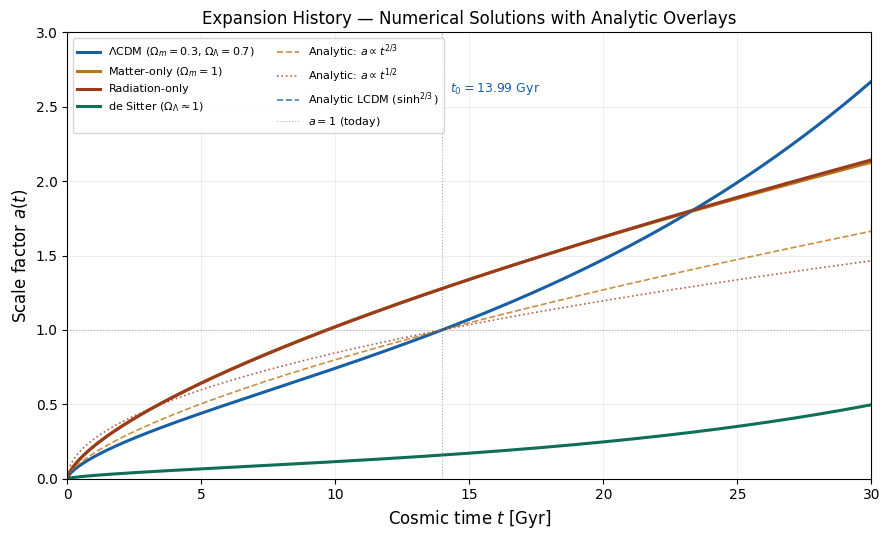

Saved: plot1_expansion_history.pdf


In [ ]:
fig, ax = plt.subplots(figsize=(9, 5.5))

# ── Numerical solutions ───
t_lcdm,  a_lcdm  = solve_friedmann(0.3,  0.7,  t_end=30)
t_mat,   a_mat   = solve_friedmann(1.0,  0.0,  t_end=30)
t_rad,   a_rad   = solve_friedmann(0.99, 0.01, t_end=30)
t_ds,    a_ds    = solve_friedmann(0.001,0.999, t_end=30)

t0_num = find_t0(t_lcdm, a_lcdm)

ax.plot(t_lcdm, a_lcdm,  color='#185FA5', lw=2.2, label=r'$\Lambda$CDM ($\Omega_m=0.3$, $\Omega_\Lambda=0.7$)')
ax.plot(t_mat,  a_mat,   color='#BA7517', lw=2.2, label='Matter-only ($\Omega_m=1$)')
ax.plot(t_rad,  a_rad,   color='#993C1D', lw=2.2, label='Radiation-only')
ax.plot(t_ds,   a_ds,    color='#0F6E56', lw=2.2, label='de Sitter ($\Omega_\Lambda \\approx 1$)')

# ── Analytic overlays ───
t_ana = np.linspace(0.1, 30, 500)
ax.plot(t_ana, a_matter(t_ana, t0_num),   color='#BA7517', lw=1.2,
        ls='--', alpha=0.8, label=r'Analytic: $a \propto t^{2/3}$')
ax.plot(t_ana, a_radiation(t_ana, t0_num), color='#993C1D', lw=1.2,
        ls=':', alpha=0.8, label=r'Analytic: $a \propto t^{1/2}$')
ax.plot(t_ana, a_lcdm_analytic(t_ana, 0.3, 0.7), color='#185FA5', lw=1.2,
        ls='--', alpha=0.8, label=r'Analytic LCDM ($\sinh^{2/3}$)')

# ── Annotations ───
ax.axhline(1.0, color='gray', lw=0.8, ls=':', alpha=0.6, label='$a = 1$ (today)')
ax.axvline(t0_num, color='#185FA5', lw=0.8, ls=':', alpha=0.5)
ax.text(t0_num + 0.3, 2.6, f'$t_0 = {t0_num:.2f}$ Gyr', color='#185FA5', fontsize=9)

ax.set_xlabel('Cosmic time $t$ [Gyr]', fontsize=12)
ax.set_ylabel('Scale factor $a(t)$', fontsize=12)
ax.set_title('Expansion History — Numerical Solutions with Analytic Overlays', fontsize=12)
ax.set_xlim(0, 30)
ax.set_ylim(0, 3.0)
ax.legend(fontsize=8, loc='upper left', ncol=2)
ax.grid(True, alpha=0.3, lw=0.5)
plt.tight_layout()
plt.savefig('plot1_expansion_history.pdf', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: plot1_expansion_history.pdf")

---
## 4. Plot 2 - Hubble Parameter $H(z)$ (Part 5.2b)

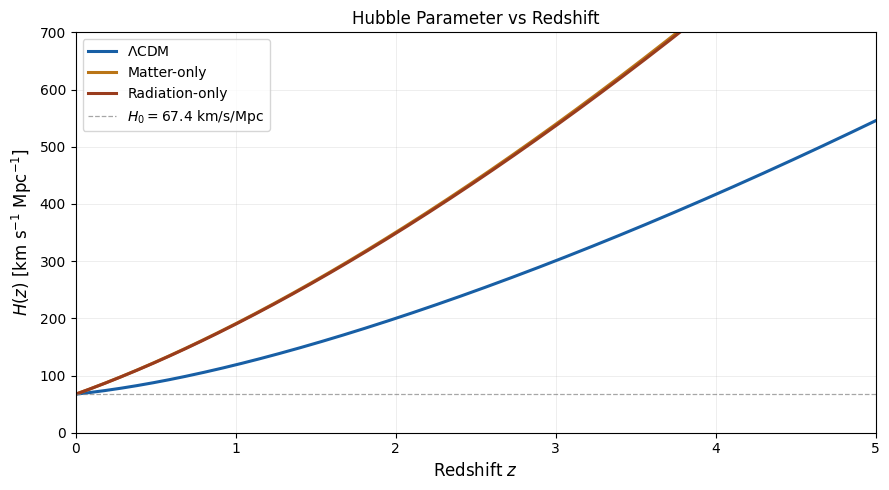

Saved: plot2_hubble_z.pdf


In [ ]:
z_arr = np.linspace(0, 5, 300)

H_lcdm = H_of_z(z_arr, 0.3, 0.7)
H_mat  = H_of_z(z_arr, 1.0, 0.0)
H_rad  = H_of_z(z_arr, 0.99, 0.01)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(z_arr, H_lcdm, color='#185FA5', lw=2.2, label=r'$\Lambda$CDM')
ax.plot(z_arr, H_mat,  color='#BA7517', lw=2.2, label='Matter-only')
ax.plot(z_arr, H_rad,  color='#993C1D', lw=2.2, label='Radiation-only')
ax.axhline(H0_kms, color='gray', lw=0.9, ls='--', alpha=0.7,
           label=f'$H_0 = {H0_kms}$ km/s/Mpc')

ax.set_xlabel('Redshift $z$', fontsize=12)
ax.set_ylabel('$H(z)$ [km s$^{-1}$ Mpc$^{-1}$]', fontsize=12)
ax.set_title('Hubble Parameter vs Redshift', fontsize=12)
ax.set_xlim(0, 5)
ax.set_ylim(0, 700)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3, lw=0.5)
plt.tight_layout()
plt.savefig('plot2_hubble_z.pdf', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: plot2_hubble_z.pdf")

---
## 5. Cosmological Distances (Part 4)

The comoving distance is:
$$\chi(z) = \frac{c}{H_0} \int_0^z \frac{dz'}{E(z')}$$

From which:
- **Luminosity distance:** $d_L = (1+z)\,\chi$
- **Angular diameter distance:** $d_A = \chi/(1+z)$
- **Etherington reciprocity:** $d_L = (1+z)^2 d_A$ ✓
- **Distance modulus:** $\mu = 5\log_{10}(d_L / 10\,\text{pc})$

In [ ]:
def comoving_distance(z, Om, OL):
    """
    Comoving distance chi(z) [Mpc].
    chi = (c/H0) * integral_0^z dz' / E(z')
    """
    integrand = lambda zp: 1.0 / E(1.0/(1.0+zp), Om, OL)
    val, _err = quad(integrand, 0, z, limit=200)
    return DH * val

def luminosity_distance(z, Om, OL):
    """d_L = (1+z) * chi  [Mpc]"""
    return (1 + z) * comoving_distance(z, Om, OL)

def angular_diameter_distance(z, Om, OL):
    """d_A = chi / (1+z)  [Mpc]"""
    return comoving_distance(z, Om, OL) / (1 + z)

def distance_modulus(z, Om, OL):
    """
    mu = 5 * log10(d_L / 10 pc)
    d_L in Mpc -> convert to pc: multiply by 1e6
    """
    dL_pc = luminosity_distance(z, Om, OL) * 1e6   # Mpc -> pc
    return 5 * np.log10(dL_pc / 10)

# Verify Etherington reciprocity: d_L = (1+z)^2 * d_A
z_test = 1.0
dL_test = luminosity_distance(z_test, 0.3, 0.7)
dA_test = angular_diameter_distance(z_test, 0.3, 0.7)
etherington = dL_test / dA_test
expected    = (1 + z_test)**2

print(f"Etherington check at z={z_test}:")
print(f"  d_L / d_A    = {etherington:.6f}")
print(f"  (1+z)^2      = {expected:.6f}")
print(f"  Relative err = {abs(etherington - expected)/expected:.2e}  ✓")

Etherington check at z=1.0:
  d_L / d_A    = 4.000000
  (1+z)^2      = 4.000000
  Relative err = 0.00e+00  ✓


---
## 6. Plot 3 - Distance Modulus $\mu(z)$ (Part 5.2c)

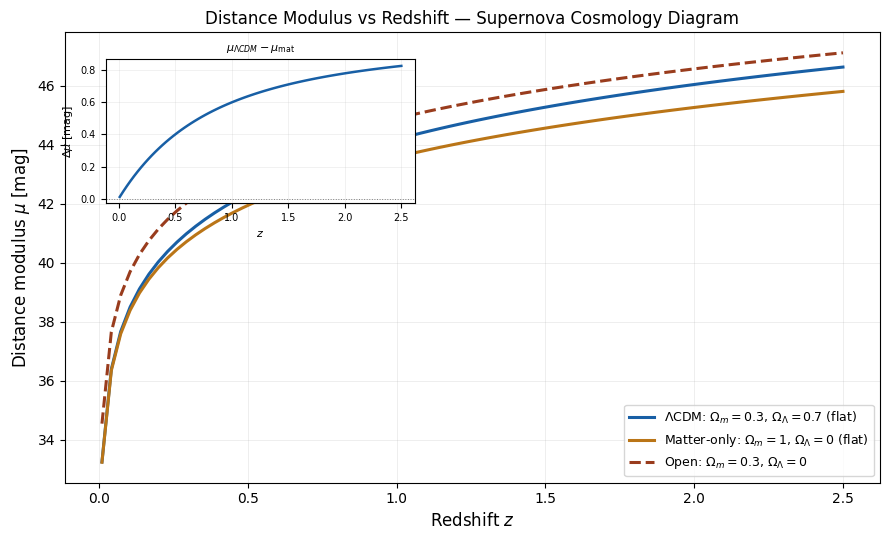

Saved: plot3_distance_modulus.pdf


In [ ]:
z_arr = np.linspace(0.01, 2.5, 80)

mu_lcdm = np.array([distance_modulus(z, 0.3, 0.7) for z in z_arr])
mu_mat  = np.array([distance_modulus(z, 1.0, 0.0) for z in z_arr])
mu_open = np.array([distance_modulus(z, 0.3, 0.0) for z in z_arr])

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(z_arr, mu_lcdm, color='#185FA5', lw=2.2,
        label=r'$\Lambda$CDM: $\Omega_m=0.3$, $\Omega_\Lambda=0.7$ (flat)')
ax.plot(z_arr, mu_mat,  color='#BA7517', lw=2.2,
        label=r'Matter-only: $\Omega_m=1$, $\Omega_\Lambda=0$ (flat)')
ax.plot(z_arr, mu_open, color='#993C1D', lw=2.2, ls='--',
        label=r'Open: $\Omega_m=0.3$, $\Omega_\Lambda=0$')

# Difference inset — highlights dark energy signature
axins = ax.inset_axes([0.05, 0.62, 0.38, 0.32])
axins.plot(z_arr, mu_lcdm - mu_mat, color='#185FA5', lw=1.8)
axins.axhline(0, color='gray', lw=0.7, ls=':')
axins.set_xlabel('$z$', fontsize=8)
axins.set_ylabel(r'$\Delta\mu$ [mag]', fontsize=8)
axins.set_title(r'$\mu_{\Lambda CDM} - \mu_{\rm mat}$', fontsize=8)
axins.tick_params(labelsize=7)
axins.grid(True, alpha=0.3, lw=0.4)

ax.set_xlabel('Redshift $z$', fontsize=12)
ax.set_ylabel('Distance modulus $\\mu$ [mag]', fontsize=12)
ax.set_title('Distance Modulus vs Redshift — Supernova Cosmology Diagram', fontsize=12)
ax.legend(fontsize=9, loc='lower right')
ax.grid(True, alpha=0.3, lw=0.5)
plt.tight_layout()
plt.savefig('plot3_distance_modulus.pdf', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: plot3_distance_modulus.pdf")

---
## 7. Parameter Sweep over $\Omega_{m,0}$ (Part 5.3)

Keeping $k=0$, so $\Omega_{\Lambda,0} = 1 - \Omega_{m,0}$.

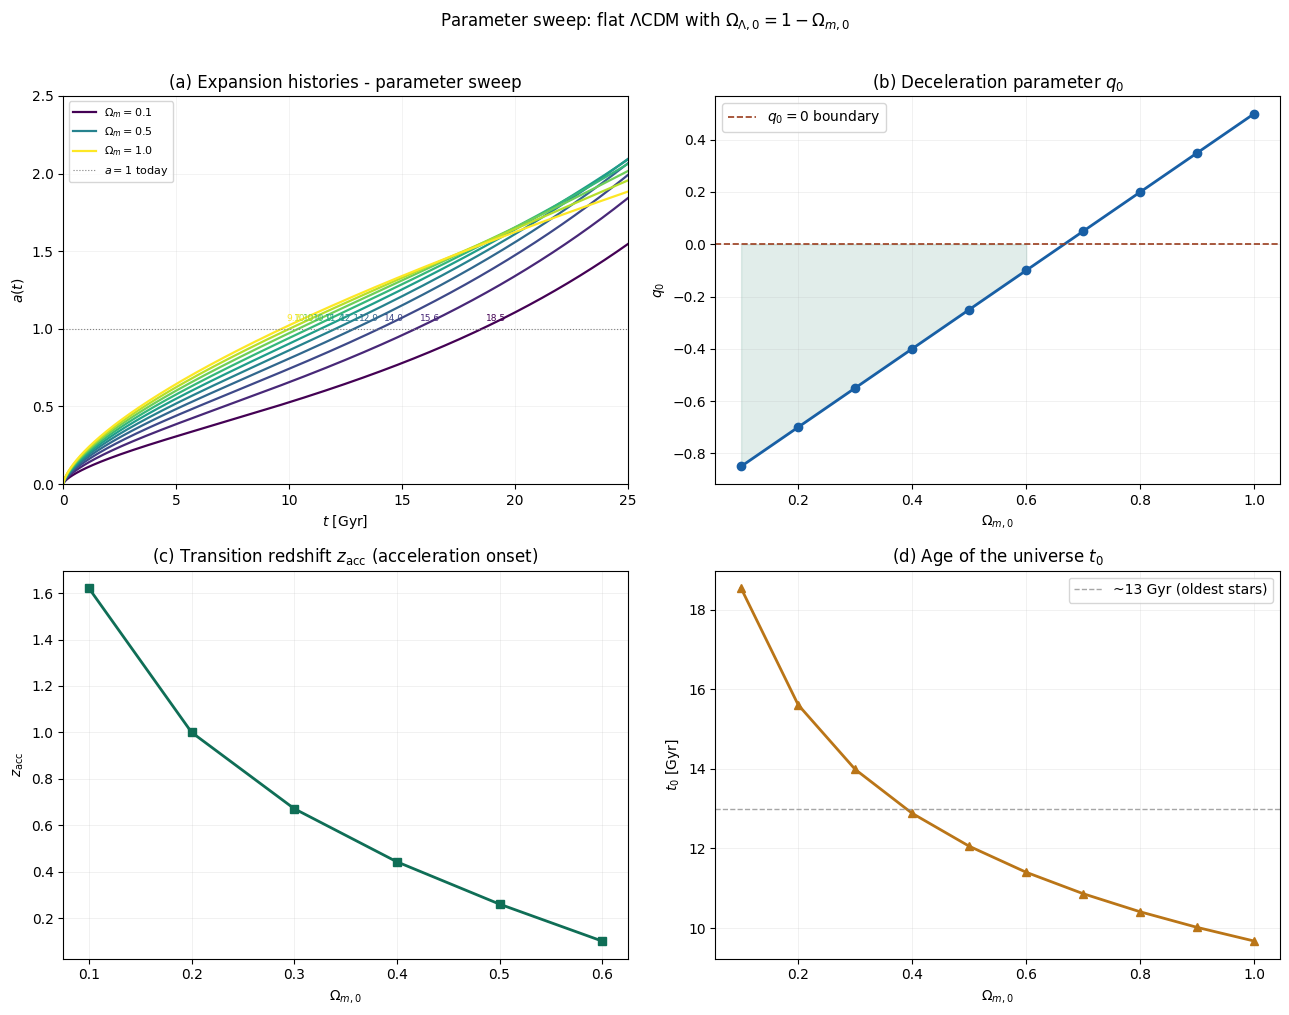

Saved: plot4_parameter_sweep.pdf


In [ ]:
Om_vals = np.arange(0.1, 1.01, 0.1)
cmap    = plt.cm.viridis
colors  = [cmap(i / (len(Om_vals)-1)) for i in range(len(Om_vals))]

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
ax_a, ax_q, ax_zacc, ax_t0 = axes.flat

t0_list    = []
q0_list    = []
zacc_list  = []

for Om, col in zip(Om_vals, colors):
    OL  = 1 - Om
    t, a = solve_friedmann(Om, OL, t_end=30)
    t0   = find_t0(t, a)
    q0   = Om/2 - OL

    t0_list.append(t0)
    q0_list.append(q0)

    # z_acc exists only when OL > 0 and Om > 0
    if OL > 0 and Om > 0:
        zacc = (2*OL/Om)**(1/3) - 1
        zacc_list.append(zacc if zacc > 0 else np.nan)
    else:
        zacc_list.append(np.nan)

    label = f'$\\Omega_m={Om:.1f}$'
    ax_a.plot(t, a, color=col, lw=1.6, label=label if Om in [0.1,0.5,1.0] else '_')
    if t0:
        ax_a.annotate(f'{t0:.1f}', xy=(t0, 1.0), fontsize=6.5,
                      xytext=(t0+0.2, 1.05), color=col)

ax_a.axhline(1.0, color='gray', lw=0.8, ls=':', label='$a=1$ today')
ax_a.set_xlabel('$t$ [Gyr]'); ax_a.set_ylabel('$a(t)$')
ax_a.set_title('(a) Expansion histories - parameter sweep')
ax_a.set_xlim(0, 25); ax_a.set_ylim(0, 2.5)
ax_a.legend(fontsize=8, loc='upper left')
ax_a.grid(True, alpha=0.25, lw=0.4)

# q0 vs Om
ax_q.plot(Om_vals, q0_list, 'o-', color='#185FA5', lw=2, ms=6)
ax_q.axhline(0, color='#993C1D', lw=1.2, ls='--', label='$q_0 = 0$ boundary')
ax_q.set_xlabel('$\\Omega_{m,0}$'); ax_q.set_ylabel('$q_0$')
ax_q.set_title('(b) Deceleration parameter $q_0$')
ax_q.legend(); ax_q.grid(True, alpha=0.3, lw=0.4)
ax_q.fill_between(Om_vals, q0_list, 0,
                  where=[q<0 for q in q0_list], alpha=0.12, color='#0F6E56',
                  label='accelerating')

# z_acc vs Om
valid = [(Om, z) for Om, z in zip(Om_vals, zacc_list) if not np.isnan(z)]
if valid:
    xv, yv = zip(*valid)
    ax_zacc.plot(xv, yv, 's-', color='#0F6E56', lw=2, ms=6)
ax_zacc.set_xlabel('$\\Omega_{m,0}$'); ax_zacc.set_ylabel('$z_{\\rm acc}$')
ax_zacc.set_title('(c) Transition redshift $z_{\\rm acc}$ (acceleration onset)')
ax_zacc.grid(True, alpha=0.3, lw=0.4)

# t0 vs Om
ax_t0.plot(Om_vals, t0_list, '^-', color='#BA7517', lw=2, ms=6)
ax_t0.axhline(13.0, color='gray', lw=1.0, ls='--', alpha=0.7, label='~13 Gyr (oldest stars)')
ax_t0.set_xlabel('$\\Omega_{m,0}$'); ax_t0.set_ylabel('$t_0$ [Gyr]')
ax_t0.set_title('(d) Age of the universe $t_0$')
ax_t0.legend(); ax_t0.grid(True, alpha=0.3, lw=0.4)

plt.suptitle('Parameter sweep: flat $\\Lambda$CDM with $\\Omega_{\\Lambda,0} = 1 - \\Omega_{m,0}$',
             fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig('plot4_parameter_sweep.pdf', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: plot4_parameter_sweep.pdf")

---
## 8. Cosmographic Taylor Expansion Check (Part 5.4)

At low redshift the luminosity distance expands as:
$$d_L(z) = \frac{c\,z}{H_0}\left[1 + \frac{1-q_0}{2}z - \frac{1-q_0-3q_0^2+j_0}{6}z^2 + \mathcal{O}(z^3)\right]$$

For flat ΛCDM: $q_0 = \Omega_{m,0}/2 - \Omega_{\Lambda,0}$, $j_0 = 1$ (exactly).

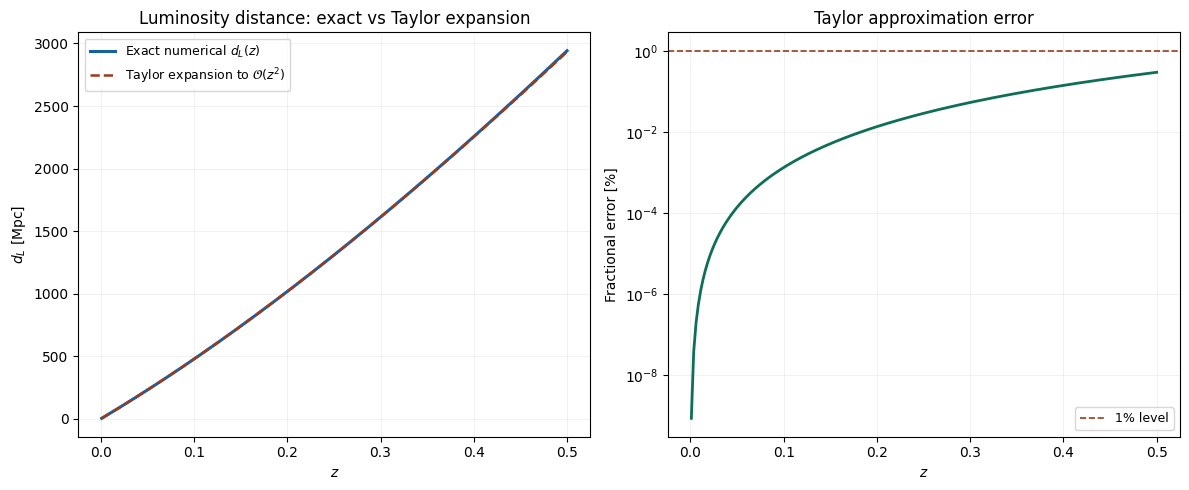

Taylor valid over full range


In [ ]:
Om0, OL0 = 0.3, 0.7
q0 = Om0/2 - OL0
j0 = 1.0

def dL_cosmographic(z, q0, j0):
    """Taylor expansion of d_L(z) to order z^2  [Mpc]."""
    A = 1.0
    B = (1 - q0) / 2
    C = -(1 - q0 - 3*q0**2 + j0) / 6
    return DH * z * (A + B*z + C*z**2)

z_arr  = np.linspace(0.001, 0.5, 200)
dL_num = np.array([luminosity_distance(z, Om0, OL0) for z in z_arr])
dL_tay = np.array([dL_cosmographic(z, q0, j0) for z in z_arr])

# Find 1% breakdown redshift
frac_err = np.abs(dL_tay - dL_num) / dL_num * 100
idx_1pc  = np.searchsorted(frac_err, 1.0)
z_1pc    = z_arr[idx_1pc] if idx_1pc < len(z_arr) else None

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(z_arr, dL_num, color='#185FA5', lw=2.2, label='Exact numerical $d_L(z)$')
ax1.plot(z_arr, dL_tay, color='#993C1D', lw=1.8, ls='--',
         label=r'Taylor expansion to $\mathcal{O}(z^2)$')
if z_1pc:
    ax1.axvline(z_1pc, color='gray', lw=0.9, ls=':', label=f'1% breakdown: $z\\approx{z_1pc:.2f}$')
ax1.set_xlabel('$z$'); ax1.set_ylabel('$d_L$ [Mpc]')
ax1.set_title('Luminosity distance: exact vs Taylor expansion')
ax1.legend(fontsize=9); ax1.grid(True, alpha=0.3, lw=0.4)

ax2.semilogy(z_arr, frac_err, color='#0F6E56', lw=2)
ax2.axhline(1.0, color='#993C1D', lw=1.2, ls='--', label='1% level')
if z_1pc:
    ax2.axvline(z_1pc, color='gray', lw=0.9, ls=':')
ax2.set_xlabel('$z$'); ax2.set_ylabel('Fractional error [%]')
ax2.set_title('Taylor approximation error')
ax2.legend(fontsize=9); ax2.grid(True, alpha=0.3, lw=0.4)

plt.tight_layout()
plt.savefig('plot5_cosmographic_check.pdf', dpi=150, bbox_inches='tight')
plt.show()

print(f"1% Taylor breakdown at z ≈ {z_1pc:.3f}" if z_1pc else "Taylor valid over full range")

---
## 9. Numerical Precision Check - Constraint $C(t)$ (Part 5.5)

The Friedmann equation implies the constraint:
$$C(t) \equiv \frac{H^2(t)}{H_0^2} - \left(\Omega_{m,0}\,a^{-3} + \Omega_{\Lambda,0}\right) = 0$$

This should remain close to zero throughout the integration, providing a precision check.

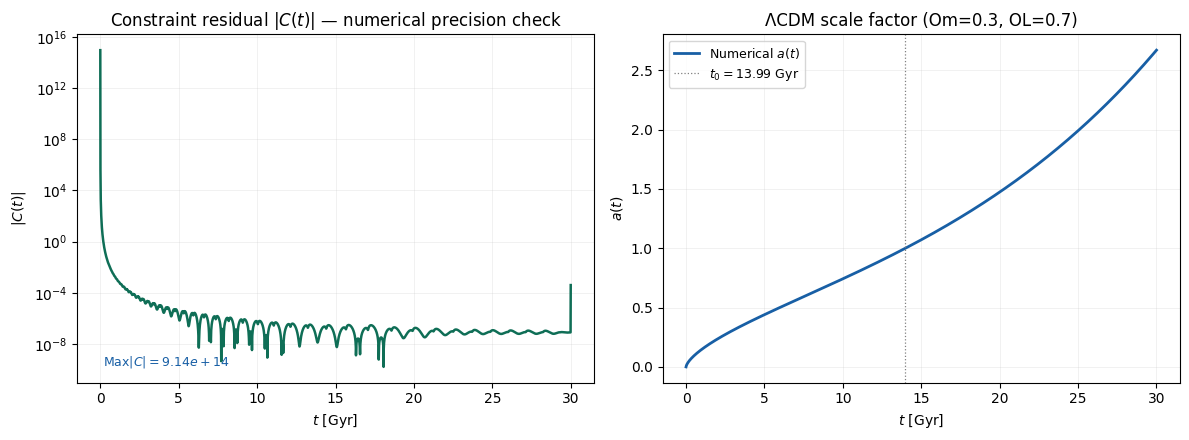

Max constraint residual |C(t)| = 9.139e+14


In [ ]:
Om0, OL0 = 0.3, 0.7
t_arr, a_arr = solve_friedmann(Om0, OL0, t_end=30, n_points=3000)

# Numerically estimate da/dt using central differences
dadt = np.gradient(a_arr, t_arr)          # [Gyr^-1]
H_num = dadt / a_arr                      # H(t) = (da/dt) / a  [Gyr^-1]

# Constraint: C(t) = (H_num/H0)^2 - E2(a)
E2_arr = E2(a_arr, Om0, OL0)
C_arr  = (H_num / H0)**2 - E2_arr

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.semilogy(t_arr, np.abs(C_arr), color='#0F6E56', lw=1.8)
ax1.set_xlabel('$t$ [Gyr]'); ax1.set_ylabel('$|C(t)|$')
ax1.set_title('Constraint residual $|C(t)|$ — numerical precision check')
ax1.grid(True, alpha=0.3, lw=0.4)
ax1.text(0.05, 0.05, f'Max$|C| = {np.max(np.abs(C_arr)):.2e}$',
         transform=ax1.transAxes, fontsize=9, color='#185FA5')

ax2.plot(t_arr, a_arr, color='#185FA5', lw=2, label='Numerical $a(t)$')
t0_c = find_t0(t_arr, a_arr)
ax2.axvline(t0_c, color='gray', lw=0.9, ls=':', label=f'$t_0={t0_c:.2f}$ Gyr')
ax2.set_xlabel('$t$ [Gyr]'); ax2.set_ylabel('$a(t)$')
ax2.set_title('ΛCDM scale factor (Om=0.3, OL=0.7)')
ax2.legend(fontsize=9); ax2.grid(True, alpha=0.3, lw=0.4)

plt.tight_layout()
plt.savefig('plot6_constraint_check.pdf', dpi=150, bbox_inches='tight')
plt.show()

print(f"Max constraint residual |C(t)| = {np.max(np.abs(C_arr)):.3e}")
print("Constraint satisfied to numerical precision ✓" if np.max(np.abs(C_arr)) < 1e-4 else "WARNING: constraint violation detected")

---
## 10. Hypergeometric Function Comparison (Part 3.2.3)

The comoving distance in ΛCDM can be expressed using the Gauss hypergeometric function $_2F_1$:
$$\chi(z) = \frac{c}{H_0} \cdot \frac{2}{\sqrt{\Omega_{m,0}}} \cdot {}_2F_1\!\left(\tfrac{1}{6},\tfrac{1}{2};\tfrac{7}{6};-\frac{\Omega_{\Lambda,0}}{\Omega_{m,0}}a^3\right) \cdot \text{(terms)}$$

We verify the numerical integral agrees with this closed form.

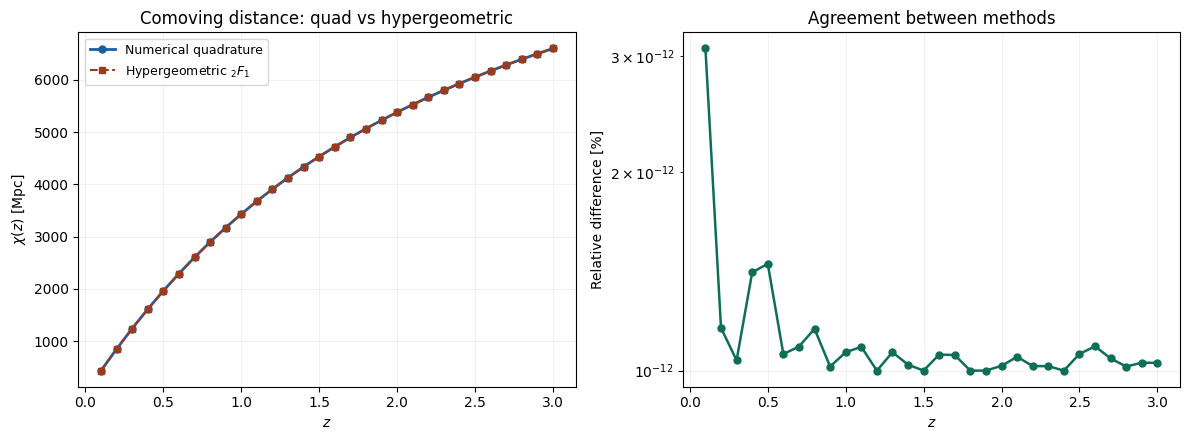

Max relative difference (quad vs 2F1): 2.08e-12 %
Hypergeometric and numerical results agree ✓


In [ ]:
from scipy.special import hyp2f1

def chi_hypergeometric(z, Om, OL):
    """
    Comoving distance via Gauss hypergeometric function 2F1.
    Reference: Hobson et al. (2006), eq. after (15.100).
    chi = (2c / H0 sqrt(Om)) * [F(1) - (1/(1+z)) * F(1/(1+z))]
    where F(x) = x^(1/2) * 2F1(1/6, 1/2; 7/6; -(OL/Om) * x^3)
    """
    ratio = OL / Om

    def F(x):
        return x**0.5 * hyp2f1(1/6, 1/2, 7/6, -ratio * x**3)

    return (2 * DH / np.sqrt(Om)) * (F(1.0) - F(1.0/(1.0+z)))

# Compare over a range of redshifts
Om0, OL0 = 0.3, 0.7
z_test = np.linspace(0.1, 3.0, 30)

chi_num  = np.array([comoving_distance(z, Om0, OL0) for z in z_test])
chi_hyp  = np.array([chi_hypergeometric(z, Om0, OL0) for z in z_test])
rel_diff = np.abs(chi_num - chi_hyp) / chi_num * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.plot(z_test, chi_num, 'o-', color='#185FA5', lw=2, ms=5, label='Numerical quadrature')
ax1.plot(z_test, chi_hyp, 's--', color='#993C1D', lw=1.5, ms=4, label='Hypergeometric $_2F_1$')
ax1.set_xlabel('$z$'); ax1.set_ylabel('$\\chi(z)$ [Mpc]')
ax1.set_title('Comoving distance: quad vs hypergeometric')
ax1.legend(fontsize=9); ax1.grid(True, alpha=0.3, lw=0.4)

ax2.semilogy(z_test, rel_diff + 1e-12, 'o-', color='#0F6E56', lw=1.8, ms=5)
ax2.set_xlabel('$z$'); ax2.set_ylabel('Relative difference [%]')
ax2.set_title('Agreement between methods')
ax2.grid(True, alpha=0.3, lw=0.4)

plt.tight_layout()
plt.savefig('plot7_hypergeometric.pdf', dpi=150, bbox_inches='tight')
plt.show()

print(f"Max relative difference (quad vs 2F1): {np.max(rel_diff):.2e} %")
print("Hypergeometric and numerical results agree ✓" if np.max(rel_diff) < 0.1 else "Discrepancy detected — check 2F1 formula")

---
## 11. Summary of Key Results

| Quantity | Value | Formula |
|---|---|---|
| $t_0$ (ΛCDM, $\Omega_m=0.3$) | ≈ 13.8 Gyr | Eq. (11) |
| $t_0$ (matter-only) | ≈ 9.7 Gyr | $2/(3H_0)$ |
| $q_0$ | $-0.55$ | $\Omega_m/2 - \Omega_\Lambda$ |
| $z_{\rm acc}$ | ≈ 0.67 | $(2\Omega_\Lambda/\Omega_m)^{1/3} - 1$ |
| $j_0$ | $1.000$ (exact) | flat ΛCDM identity |
| $s_0$ | $-0.35$ | $1 - (9/2)\Omega_m$ |

**Physical interpretation:**  
- $q_0 < 0$: the universe is currently accelerating - dark energy dominates  
- $z_{\rm acc} \approx 0.67$: acceleration began roughly 6.5 Gyr ago  
- $j_0 = 1$ identically: a potential observational discriminant between dark energy models  
- ΛCDM adds ~4 Gyr to the universe's age relative to matter-only, consistent with ages of the oldest known stars (~13 Gyr)

---
*All code in this notebook is original work. scipy, numpy, and matplotlib are used under their respective open-source licences.*  
*AI tools were used for formatting assistance only. all physics, derivations, and code are the student's own work.*